In [21]:
#import libraries

import numpy as np
import pandas as pd

df = pd.read_csv('retail_dynamics_weekly_sales.csv')

# Task 1

## Structure Analysis

get general overview of the dataset's structure

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   StoreID  1500 non-null   str    
 1   Week     1500 non-null   int64  
 2   Price    1500 non-null   float64
 3   Display  1500 non-null   str    
 4   Media    1500 non-null   int64  
 5   Sales    1500 non-null   int64  
dtypes: float64(1), int64(3), str(2)
memory usage: 80.5 KB


inspect the first 5 rows for each variable to glean how data is represented in the dataset

In [3]:
df.head(5)

,StoreID,Week,Price,Display,Media,Sales
0,S1115,2,8.74,No,0,295
1,S1076,2,9.31,N,0,234
2,S1102,3,10.53,no,0,237
3,S1057,8,13.45,No,1,225
4,S1102,6,9.01,no,0,233


quick summary of dataset size i.e. row/column count

In [4]:
df.shape

(1500, 6)

## Content Analysis

#### Frequency analysis 

In [5]:
display_freq = ["Display"]

for row in display_freq:
    print(df[display_freq].value_counts(dropna=False))

Display
No         364
N          337
no         333
Y          166
yes        155
Yes        145
Name: count, dtype: int64


#### Unique identifer check

In [29]:
print("Unique StoreIDs:", df["StoreID"].nunique())
print("Duplicate StoreIDs:", df["StoreID"].duplicated().sum())
print(df["StoreID"].nunique() == len(df))

Unique StoreIDs: 150
Duplicate StoreIDs: 1350
False


#### Duplicate record check

check for duplicate records in dataset

In [6]:
df.duplicated().sum()

np.int64(0)

#### Invalid and Missing Data Analysis

check for invalid weeks (i.e. equal to or less than one, or greater than 53)

In [7]:
df[~df['Week'].between(0, 52)]

,StoreID,Week,Price,Display,Media,Sales


check for invalid strings in categorical columns

In [31]:
invalid_str = df[['Display', 'StoreID']].isin(["?", ""])
print(invalid_str.sum())

Display    0
StoreID    0
dtype: int64


check for nulls

In [9]:
df.isnull().sum()

StoreID    0
Week       0
Price      0
Display    0
Media      0
Sales      0
dtype: int64

## Descriptive Statistics 

#### Statistical Summary for numerical columns

In [10]:
df.describe(include='number').round(2)

,Week,Price,Media,Sales
count,1500.00,1500.00,1500.00,1500.00
mean,5.50,11.98,0.25,235.65
std,2.87,2.16,0.43,42.90
min,1.00,6.50,0.00,120.00
25%,3.00,10.52,0.00,206.00
50%,5.50,11.97,0.00,234.00
75%,8.00,13.48,1.00,264.00
max,10.00,17.25,1.00,360.00


Examine sales specifically

In [11]:
df['Sales'].describe().round(2)

count    1500.00
mean      235.65
std        42.90
min       120.00
25%       206.00
50%       234.00
75%       264.00
max       360.00
Name: Sales, dtype: float64

### Sales behaviour analysis

Distribution of Sales

<Axes: >

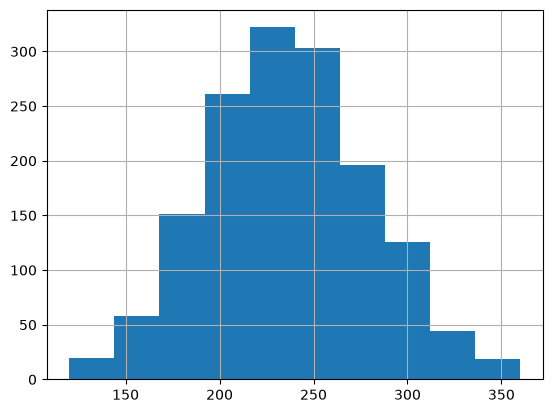

In [12]:
df['Sales'].hist()

sales by store

In [34]:
Store_sales = df.groupby('StoreID')['Sales'].mean()

store_sales.describe().round(2)

count    150.00
mean     235.65
std       21.68
min      179.50
25%      220.42
50%      234.75
75%      250.42
max      285.50
Name: Sales, dtype: float64

Calculate stores with top 5 lowest vs highest sales

In [37]:
print("Lowest average sales:")
print(store_sales.nsmallest(5))

print("\nHighest average sales:")
print(store_sales.nlargest(5))

Lowest average sales:
StoreID
S1120    179.5
S1100    186.8
S1085    190.7
S1031    199.4
S1103    199.8
Name: Sales, dtype: float64

Highest average sales:
StoreID
S1080    285.5
S1063    285.0
S1105    284.6
S1130    281.1
S1137    279.2
Name: Sales, dtype: float64


##### Sales under Display vs No display

In [40]:
df.groupby('Display')['Sales'].mean().round(2)

Display
N      224.93
No     221.64
Y      259.40
Yes    263.12
no     224.76
yes    264.16
Name: Sales, dtype: float64

#### Sales under Media vs No Media

In [42]:
media_sales = df.groupby('Media')['Sales'].mean().round(2)

print("No Media:", media_sales[0])
print("Media:", media_sales[1])

No Media: 228.37
Media: 257.19


#### Sales under Higher price vs lower price

find median price to establish higher/lower boundary cutoff

In [45]:
price_median = df['Price'].median()

print("Median Price:", price_median)

Median Price: 11.97


create a temporary price level category 

In [47]:
df['Price_Level'] = np.where(
    df['Price'] >= price_median,
    'Higher Price',
    'Lower Price'
)

check that worked

In [49]:
df['Price_Level'].value_counts()

Price_Level
Higher Price    751
Lower Price     749
Name: count, dtype: int64

#### avg sales at higher vs lower price level

In [51]:
price_sales = df.groupby('Price_Level')['Sales'].mean().round(2)
price_sales

Price_Level
Higher Price    220.62
Lower Price     250.73
Name: Sales, dtype: float64

In [53]:
df['Display'].value_counts()

Display
No     364
N      337
no     333
Y      166
yes    155
Yes    145
Name: count, dtype: int64

#### Sales comparison

In [56]:
## create temporary var to group different y/n representations
display_yes = display_sales['Yes'] + display_sales['Y'] + display_sales['yes']
display_no = display_sales['No'] + display_sales['N'] + display_sales['no']

comparison = pd.DataFrame({
    'Condition': [
        'Display',
        'No Display',
        'Media',
        'No Media',
        'Higher Price',
        'Lower Price'
    ],
    'Average Sales': [
        display_sales['Yes'],
        display_sales['No'],
        media_sales[1],
        media_sales[0],
        price_sales['Higher Price'],
        price_sales['Lower Price']
    ]
})

comparison

,Condition,Average Sales
0,Display,263.12
1,No Display,221.64
2,Media,257.19
3,No Media,228.37
4,Higher Price,220.62
5,Lower Price,250.73


<Axes: title={'center': 'Average Weekly Sales by Promotional Condition'}, xlabel='Condition', ylabel='Average Sales (units)'>

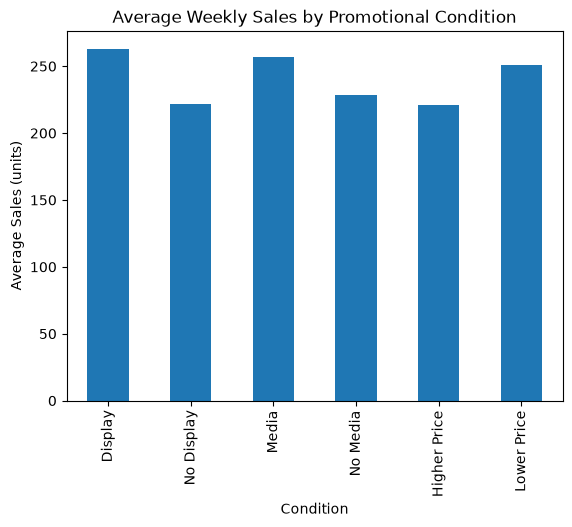

In [57]:
comparison.plot(
    x='Condition',
    y='Average Sales',
    kind='bar',
    legend=False,
    title='Average Weekly Sales by Promotional Condition',
    ylabel='Average Sales (units)'
)

# Task 2

## Data Cleansing

#### Mapping

standardise different values as per frequency analysis

In [ ]:
df['Display'] = df['Display'].str.strip().str.lower()

Binary encode Display such that No = 0 and Yes = 1

In [ ]:
df['Display'] = df['Display'].replace({
    'no': 0,
    'n': 0,
    'yes': 1,
    'y': 1
})

Check encoding

In [ ]:
df['Display'].value_counts(dropna=False)